# Deep sigmoid network — Xavier initialization + Adam

**Model:** fully connected deep neural network, **sigmoid** hidden activations,
**Xavier (normalized) initialization**, **Adam** optimizer, single logit output
for binary classification of `HeartDisease`.

**Metrics recorded everywhere:** accuracy, recall (sensitivity), ROC-AUC.

### Why this exact combination
Glorot & Bengio (2010) show that with the classic initialization
$W \sim U[-1/\sqrt{n}, 1/\sqrt{n}]$ the back-propagated gradient shrinks layer by
layer, so deep nets train badly. Their fix is the *normalized* initialization
(their eq. 16), which keeps the forward and backward variance roughly constant
across layers. Adam attacks the same symptom from the other side: it rescales
each parameter's step by a running estimate of its own gradient magnitude, so a
layer with tiny gradients still gets a usable step size.

This notebook is the **Xavier + Adam** 

### What the notebook does, in order
1. Load the **shared** train / validation / test split (same rows every model in
   the project uses, so the numbers are comparable).
2. Build the network and verify the initialization numerically against eq. 16.
3. Train with mini-batch Adam, **checkpointing the weights whenever validation
   AUC improves**, and early-stopping when it stops improving. The returned model
   is the best checkpoint, not the last epoch.
4. Choose depth and learning rate **on the validation set only**.
5. Retrain the chosen configuration, save its weights to `models/`, and look at
   the test set **once**, at the very end.

## Environment

The guard below installs anything missing, so the notebook runs the same in
Colab and locally. Nothing else in the notebook touches the internet.

In [1]:
import importlib.util, subprocess, sys

# install only what is actually absent (Colab already has most of these)
PIP_NAME = {"sklearn": "scikit-learn"}
for pkg in ["torch", "sklearn", "pandas", "numpy", "matplotlib"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        PIP_NAME.get(pkg, pkg)], check=True)

import copy, math, pathlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, accuracy_score, recall_score,
                             precision_score, f1_score, confusion_matrix,
                             roc_curve)

torch.set_num_threads(4)          # keep CPU training predictable
plt.rcParams["figure.dpi"] = 110
print("torch", torch.__version__)

torch 2.15.0


## 1. Data — the shared three-way split

`data_preprocessing.ipynb` writes three files. **Do not re-split anything here.**
| file | rows | role |
|---|---|---|
| `heart_train_processed.csv` | 587 | gradient updates |
| `heart_val_processed.csv` | 147 | early stopping, depth and learning-rate choice |
| `heart_test_processed.csv` | 184 | touched once, in the final section |

Features are already scaled and one-hot encoded upstream, so there is no fitting
of any transformer in this notebook, which also means no risk of leaking test
statistics into training.

In [2]:
# locate cleaned_data/ whether we run from the repo root, a subfolder, or Colab
def find_cleaned_dir():
    here = pathlib.Path.cwd()
    for base in [here, *here.parents, pathlib.Path("/content")]:
        p = base / "cleaned_data"
        if (p / "heart_train_processed.csv").exists():
            return p
    raise FileNotFoundError(
        "cleaned_data/ not found. In Colab, upload the three "
        "heart_*_processed.csv files into a folder named cleaned_data/.")

CLEAN = find_cleaned_dir()
tr_df  = pd.read_csv(CLEAN / "heart_train_processed.csv")
val_df = pd.read_csv(CLEAN / "heart_val_processed.csv")
test_df = pd.read_csv(CLEAN / "heart_test_processed.csv")

TARGET = "HeartDisease"
FEATURES = [c for c in tr_df.columns if c != TARGET]
N_FEATURES = len(FEATURES)

for name, d in [("train", tr_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} {d.shape[0]:4d} rows   positive rate {d[TARGET].mean():.4f}")
print(f"\n{N_FEATURES} features:", ", ".join(FEATURES))

# cheap guard: the three files must not share any row
as_rows = lambda d: set(map(tuple, d.round(10).values))
a, b, c = as_rows(tr_df), as_rows(val_df), as_rows(test_df)
assert not (a & b) and not (a & c) and not (b & c), "splits overlap!"
print("\nno overlap between the three splits")

train  587 rows   positive rate 0.5537
val    147 rows   positive rate 0.5510
test   184 rows   positive rate 0.5543

16 features: Age, Sex, RestingBP, Cholesterol, FastingBS, MaxHR, ExerciseAngina, Oldpeak, Chol_missing, ChestPainType_ATA, ChestPainType_NAP, ChestPainType_TA, RestingECG_Normal, RestingECG_ST, ST_Slope_Flat, ST_Slope_Up

no overlap between the three splits


### Tensors

Everything fits in memory many times over (918 rows total), so there is no
`DataLoader` ,  we index a permutation directly, which is faster and makes the
shuffling reproducible from a single seed.

In [3]:
def to_tensors(d):
    X = torch.tensor(d[FEATURES].values, dtype=torch.float32)
    y = torch.tensor(d[TARGET].values,  dtype=torch.float32)   # BCE wants float
    return X, y

X_tr,  y_tr  = to_tensors(tr_df)
X_val, y_val = to_tensors(val_df)
X_te,  y_te  = to_tensors(test_df)
print(X_tr.shape, X_val.shape, X_te.shape)

torch.Size([587, 16]) torch.Size([147, 16]) torch.Size([184, 16])


## 2. The network  

  
$$h^{(0)} = x, \qquad h^{(k)} = \sigma\!\left(W^{(k)} h^{(k-1)} + b^{(k)}\right),
\qquad \text{output} = W^{(L)} h^{(L-1)} + b^{(L)}$$

with $\sigma(z) = 1/(1+e^{-z})$ on every hidden layer. The output layer stays
**linear** and emits a logit; the sigmoid that turns it into a probability lives
inside `BCEWithLogitsLoss`, which fuses the two using log-sum-exp and is
numerically stable where `sigmoid()` followed by `BCELoss()` is not.

### Xavier (normalized) initialization — eq. 16 of the paper

$$W_{ij} \sim U\!\left[-\frac{\sqrt 6}{\sqrt{n_{in}+n_{out}}},\;
                        +\frac{\sqrt 6}{\sqrt{n_{in}+n_{out}}}\right]$$

The $\sqrt 6$ is not arbitrary. A uniform distribution on $[-b, b]$ has variance
$b^2/3$, and the derivation asks for $\mathrm{Var}[W] = 2/(n_{in}+n_{out})$;
setting $b^2/3 = 2/(n_{in}+n_{out})$ gives exactly $b = \sqrt{6/(n_{in}+n_{out})}$.
Biases start at zero , they carry no variance argument.

PyTorch's default `nn.Linear` initialization is *not* this; it is
$U[-1/\sqrt{n_{in}}, 1/\sqrt{n_{in}}]$, which is the paper's **old** eq. 1. So the
init has to be overwritten explicitly, which is what `apply_xavier` does.

In [4]:
WIDTH = 32          # hidden units per layer, fixed so depth is the only size knob

# depth-L fully connected net: sigmoid hidden units, Xavier-initialized weights
class SigmoidNet(nn.Module):

    def __init__(self, n_in, width, depth, seed=0):
        super().__init__()
        torch.manual_seed(seed)                       # reproducible weights
        dims = [n_in] + [width] * depth
        self.hidden = nn.ModuleList(
            [nn.Linear(dims[i], dims[i + 1]) for i in range(depth)])
        self.out = nn.Linear(dims[-1], 1)             # linear -> logit
        self.apply_xavier()

    def apply_xavier(self):
        for lin in list(self.hidden) + [self.out]:
            n_in, n_out = lin.in_features, lin.out_features
            bound = math.sqrt(6.0) / math.sqrt(n_in + n_out)   # eq. (16)
            nn.init.uniform_(lin.weight, -bound, bound)
            nn.init.zeros_(lin.bias)

    def forward(self, x):
        h = x
        for lin in self.hidden:
            h = torch.sigmoid(lin(h))                 # sigmoid everywhere hidden
        return self.out(h).squeeze(-1)                # shape (batch,)

print(SigmoidNet(N_FEATURES, WIDTH, 3))

SigmoidNet(
  (hidden): ModuleList(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1-2): 2 x Linear(in_features=32, out_features=32, bias=True)
  )
  (out): Linear(in_features=32, out_features=1, bias=True)
)


### Checking the initialization numerically
an initialization bug is silent , the net still trains, just
worse so confirm the weights really match eq. 16 before drawing conclusions
from them. Measured std should equal $b/\sqrt3$ for a uniform on $[-b, b]$.

In [5]:
net = SigmoidNet(N_FEATURES, WIDTH, 4, seed=0)
rows = []
for k, lin in enumerate(list(net.hidden) + [net.out], start=1):
    n_in, n_out = lin.in_features, lin.out_features
    b = math.sqrt(6.0) / math.sqrt(n_in + n_out)
    rows.append({"layer": k, "n_in": n_in, "n_out": n_out,
                 "bound b": b,
                 "theory std = b/sqrt(3)": b / math.sqrt(3),
                 "measured std": lin.weight.std().item(),
                 "max |W| <= b": bool(lin.weight.abs().max().item() <= b)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

 layer  n_in  n_out  bound b  theory std = b/sqrt(3)  measured std  max |W| <= b
     1    16     32   0.3536                  0.2041        0.2033          True
     2    32     32   0.3062                  0.1768        0.1757          True
     3    32     32   0.3062                  0.1768        0.1765          True
     4    32     32   0.3062                  0.1768        0.1762          True
     5    32      1   0.4264                  0.2462        0.2304          True


## 3. Metrics


- **AUC** — ranking quality, independent of any threshold. Used for model
  selection, because it does not move when the decision threshold moves.
- **Accuracy** — fraction correct at the chosen threshold. The majority class is
  ~55%, so anything near that is worthless.
- **Recall** (sensitivity, TPR)  of the patients who *do* have heart disease,
  the fraction we flag. This is the one that matters clinically: a missed case is
  far worse than a false alarm. Recall depends entirely on the threshold, so the
  threshold is stated wherever recall is reported (0.5 unless said otherwise, and
  §7 tunes it on validation).

In [6]:
LOSS_FN = nn.BCEWithLogitsLoss()      # sigmoid + BCE fused, numerically stable

# loss + AUC + accuracy + recall on one split, at a given threshold
@torch.no_grad()
def evaluate(net, X, y, thresh=0.5):
    net.eval()
    logits = net(X)
    prob = torch.sigmoid(logits).numpy()
    yt = y.numpy()
    pred = (prob >= thresh).astype(int)
    return {"loss":   float(LOSS_FN(logits, y)),
            "auc":    float(roc_auc_score(yt, prob)),
            "acc":    float(accuracy_score(yt, pred)),
            "recall": float(recall_score(yt, pred, zero_division=0))}

## 4. Training loop

In [7]:
# train one Xavier+Adam sigmoid net -> (best net, best-epoch metrics, history)
def train_model(depth, lr, seed=0, width=WIDTH, max_epochs=300,
                patience=30, batch_size=32, verbose=False):
    torch.manual_seed(seed)
    net = SigmoidNet(N_FEATURES, width, depth, seed=seed)
    opt = torch.optim.Adam(net.parameters(), lr=lr)

    g = torch.Generator().manual_seed(seed)    # reproducible batch shuffling
    n = X_tr.shape[0]
    best, hist, stale = {"auc": -1.0}, [], 0

    for ep in range(1, max_epochs + 1):
        net.train()
        perm = torch.randperm(n, generator=g)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            LOSS_FN(net(X_tr[idx]), y_tr[idx]).backward()
            opt.step()

        tr, va = evaluate(net, X_tr, y_tr), evaluate(net, X_val, y_val)
        hist.append({"epoch": ep,
                     **{f"train_{k}": v for k, v in tr.items()},
                     **{f"val_{k}":   v for k, v in va.items()}})

        if va["auc"] > best["auc"] + 1e-5:          # improvement -> checkpoint
            best = {**va, "epoch": ep,
                    "state": copy.deepcopy(net.state_dict())}
            stale = 0
        else:
            stale += 1
            if stale >= patience:                   # no progress -> stop
                break
        if verbose and ep % 25 == 0:
            print(f"  ep {ep:3d}  val auc {va['auc']:.4f}  (best {best['auc']:.4f} @ {best['epoch']})")

    net.load_state_dict(best["state"])              # restore the best weights
    return net, best, pd.DataFrame(hist)

### Sanity check before any sweep

One shallow run with a middling learning rate. If this does not clearly beat the
55% majority baseline, something is wrong with the data or the loop and the whole
sweep below would be wasted compute.

In [8]:
_, sanity, sanity_hist = train_model(depth=2, lr=1e-3, seed=0, verbose=True)
print(f"\nbest epoch {sanity['epoch']} of {len(sanity_hist)} run")
print(f"val  auc {sanity['auc']:.4f}   acc {sanity['acc']:.4f}   recall {sanity['recall']:.4f}")
print(f"majority-class accuracy on val = {max(1 - y_val.mean(), y_val.mean()):.4f}")

  ep  25  val auc 0.9332  (best 0.9332 @ 25)
  ep  50  val auc 0.9304  (best 0.9336 @ 29)

best epoch 29 of 59 run
val  auc 0.9336   acc 0.8844   recall 0.8765
majority-class accuracy on val = 0.5510


## 5. Choosing depth and learning rate (validation only)

Adam is sensitive to its learning rate, and depth is the thing the paper cares
about, so both are swept rather than guessed. Three seeds per cell because a
single run on 587 rows is noisy , the mean is what gets compared, and the spread
tells us whether a difference is real.

In [9]:
DEPTHS  = [1, 2, 3, 4, 5]
LR_GRID = [3e-4, 1e-3, 3e-3, 1e-2]
SEEDS   = [0, 1, 2]

records = []
for depth in DEPTHS:
    for lr in LR_GRID:
        for seed in SEEDS:
            _, best, _ = train_model(depth=depth, lr=lr, seed=seed)
            records.append({"depth": depth, "lr": lr, "seed": seed,
                            "val_auc": best["auc"], "val_acc": best["acc"],
                            "val_recall": best["recall"], "best_epoch": best["epoch"]})
    print(f"depth {depth} done")

sweep = pd.DataFrame(records)
agg = (sweep.groupby(["depth", "lr"])
            .agg(val_auc=("val_auc", "mean"), auc_sd=("val_auc", "std"),
                 val_acc=("val_acc", "mean"), val_recall=("val_recall", "mean"),
                 epochs=("best_epoch", "mean"))
            .reset_index())

print("\nMean validation AUC over 3 seeds:\n")
print(agg.pivot(index="depth", columns="lr", values="val_auc").round(4).to_string())

depth 1 done


depth 2 done


depth 3 done


depth 4 done


depth 5 done

Mean validation AUC over 3 seeds:

lr     0.0003  0.0010  0.0030  0.0100
depth                                
1      0.9335  0.9337  0.9340  0.9335
2      0.9333  0.9336  0.9337  0.9335
3      0.9330  0.9330  0.9328  0.9326
4      0.9351  0.9346  0.9350  0.9345
5      0.9339  0.9335  0.9335  0.9338


In [10]:
print("Mean validation accuracy:\n")
print(agg.pivot(index="depth", columns="lr", values="val_acc").round(4).to_string())
print("\nMean validation recall (threshold 0.5):\n")
print(agg.pivot(index="depth", columns="lr", values="val_recall").round(4).to_string())
print("\nSeed-to-seed std of validation AUC (stability):\n")
print(agg.pivot(index="depth", columns="lr", values="auc_sd").round(4).to_string())

Mean validation accuracy:

lr     0.0003  0.0010  0.0030  0.0100
depth                                
1      0.8866  0.8912  0.8889  0.8889
2      0.8912  0.8912  0.8934  0.8980
3      0.8934  0.8912  0.8866  0.8821
4      0.8821  0.8798  0.8912  0.8844
5      0.8980  0.8957  0.8912  0.8776

Mean validation recall (threshold 0.5):

lr     0.0003  0.0010  0.0030  0.0100
depth                                
1      0.8848  0.8889  0.8848  0.8889
2      0.8930  0.8889  0.8971  0.9218
3      0.8971  0.8930  0.8848  0.8889
4      0.8765  0.8724  0.8889  0.8807
5      0.9012  0.8971  0.8971  0.8765

Seed-to-seed std of validation AUC (stability):

lr     0.0003  0.0010  0.0030  0.0100
depth                                
1      0.0010  0.0014  0.0020  0.0016
2      0.0003  0.0004  0.0013  0.0008
3      0.0011  0.0011  0.0017  0.0026
4      0.0010  0.0008  0.0011  0.0011
5      0.0014  0.0014  0.0010  0.0030


### Reading the sweep

The figure plots validation AUC against depth, one line per learning rate.   

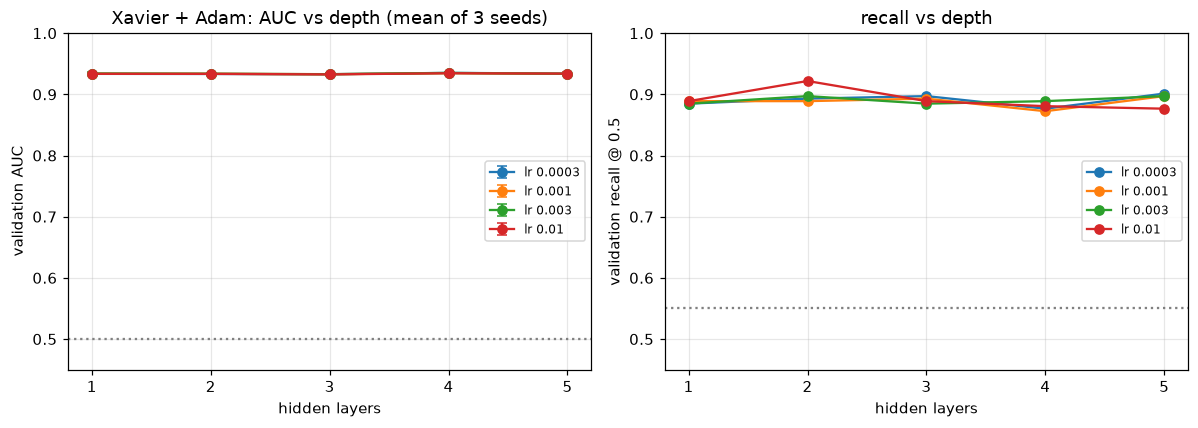

In [11]:
FIGDIR = pathlib.Path("figures"); FIGDIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for lr in LR_GRID:
    s = agg[agg.lr == lr]
    ax[0].errorbar(s.depth, s.val_auc, yerr=s.auc_sd, marker="o",
                   capsize=3, label=f"lr {lr:g}")
    ax[1].plot(s.depth, s.val_recall, marker="o", label=f"lr {lr:g}")

ax[0].set(xlabel="hidden layers", ylabel="validation AUC",
          title="Xavier + Adam: AUC vs depth (mean of 3 seeds)")
ax[0].axhline(0.5, ls=":", c="grey")                 # chance
ax[1].set(xlabel="hidden layers", ylabel="validation recall @ 0.5",
          title="recall vs depth")
ax[1].axhline(float(y_val.mean()), ls=":", c="grey")  # recall of "always predict 1"
# both panels share an honest 0.45-1.0 scale: auto-scaling a flat line would
# magnify seed noise into what looks like a trend
for a in ax:
    a.set_ylim(0.45, 1.0)
    a.set_xticks(DEPTHS); a.legend(fontsize=8); a.grid(alpha=.3)
fig.tight_layout()
fig.savefig(FIGDIR / "fig_xavier_adam_depth_lr.png", bbox_inches="tight")
plt.show()

## 6. Final model - retrain, inspect, save the weights

The configuration with the highest mean validation AUC wins : plain argmax on
the sweep above.

Every cell of that grid sits inside a ~0.002 AUC band, which is smaller than the seed-to-seed spread. So the winning *depth* is not meaningfully better than the others; the finding is the flatness
itself. With Xavier initialization and Adam, depth simply stops mattering on this
dataset, which is exactly the contrast the standard-initialization arms need.

It is then retrained on seed 0 and its best-AUC weights are written to
`models/dnn_xavier_adam.pt`, together with the metadata needed to rebuild the
architecture (depth, width, feature order). Loading a `state_dict` into the wrong
shape fails loudly; loading it with the columns in a different order fails
silently, which is why `features` is stored.

In [12]:
# plain argmax of mean validation AUC over the grid
chosen = agg.sort_values("val_auc", ascending=False).iloc[0]
BEST_DEPTH, BEST_LR = int(chosen.depth), float(chosen.lr)
print(f"chosen: depth {BEST_DEPTH}, lr {BEST_LR:g}  (mean val auc {chosen.val_auc:.4f})")

# how big is the whole grid's spread? if it is small, the choice is near-arbitrary
spread = agg.val_auc.max() - agg.val_auc.min()
print(f"spread of mean val AUC across all {len(agg)} configs: {spread:.4f}")
print(f"median seed-to-seed std within a config:            {agg.auc_sd.median():.4f}")

final_net, final_best, hist = train_model(depth=BEST_DEPTH, lr=BEST_LR,
                                          seed=0, verbose=True)
print(f"\nbest weights are from epoch {final_best['epoch']} "
      f"(trained {len(hist)} epochs, then early-stopped)")
print(f"val  auc {final_best['auc']:.4f}   acc {final_best['acc']:.4f}   "
      f"recall {final_best['recall']:.4f}")

chosen: depth 4, lr 0.0003  (mean val auc 0.9351)
spread of mean val AUC across all 20 configs: 0.0025
median seed-to-seed std within a config:            0.0011


  ep  25  val auc 0.9072  (best 0.9072 @ 25)


  ep  50  val auc 0.9317  (best 0.9317 @ 48)


  ep  75  val auc 0.9334  (best 0.9355 @ 62)



best weights are from epoch 62 (trained 92 epochs, then early-stopped)
val  auc 0.9355   acc 0.8707   recall 0.8642


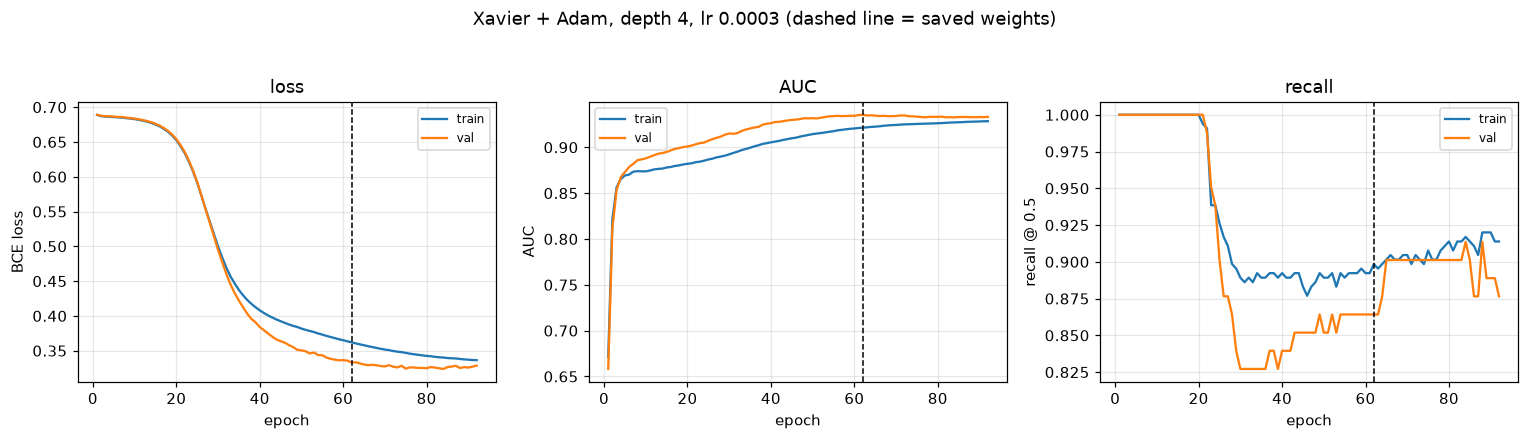

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(hist.epoch, hist.train_loss, label="train")
ax[0].plot(hist.epoch, hist.val_loss, label="val")
ax[0].set(xlabel="epoch", ylabel="BCE loss", title="loss")
ax[1].plot(hist.epoch, hist.train_auc, label="train")
ax[1].plot(hist.epoch, hist.val_auc, label="val")
ax[1].set(xlabel="epoch", ylabel="AUC", title="AUC")
ax[2].plot(hist.epoch, hist.train_recall, label="train")
ax[2].plot(hist.epoch, hist.val_recall, label="val")
ax[2].set(xlabel="epoch", ylabel="recall @ 0.5", title="recall")
for a in ax:
    a.axvline(final_best["epoch"], c="k", ls="--", lw=1)   # the saved checkpoint
    a.legend(fontsize=8); a.grid(alpha=.3)
fig.suptitle(f"Xavier + Adam, depth {BEST_DEPTH}, lr {BEST_LR:g} "
             f"(dashed line = saved weights)", y=1.04)
fig.tight_layout()
fig.savefig(FIGDIR / "fig_xavier_adam_training.png", bbox_inches="tight")
plt.show()

In [14]:
MODELDIR = pathlib.Path("models"); MODELDIR.mkdir(exist_ok=True)
ckpt_path = MODELDIR / "dnn_xavier_adam.pt"

torch.save({"state_dict": final_net.state_dict(),
            "init": "xavier_normalized_eq16",
            "activation": "sigmoid",
            "optimizer": "adam",
            "depth": BEST_DEPTH, "width": WIDTH, "lr": BEST_LR,
            "n_features": N_FEATURES, "features": FEATURES,
            "best_epoch": final_best["epoch"],
            "val_auc": final_best["auc"],
            "val_acc": final_best["acc"],
            "val_recall": final_best["recall"]}, ckpt_path)
print("saved", ckpt_path.resolve())

# reload into a fresh net and confirm the weights round-trip exactly
ck = torch.load(ckpt_path, weights_only=False)
reloaded = SigmoidNet(ck["n_features"], ck["width"], ck["depth"])
reloaded.load_state_dict(ck["state_dict"])
assert evaluate(reloaded, X_val, y_val)["auc"] == final_best["auc"]
print("reload check passed - saved weights reproduce the validation AUC exactly")

saved /Users/kyisinthant/Documents/ECS171-Project/models/dnn_xavier_adam.pt
reload check passed - saved weights reproduce the validation AUC exactly


### The flat start is not a bug

Expect the first ~20 epochs to sit at a loss of about **0.693** = $\ln 2$ with
recall pinned at 1.0. That is the net emitting one constant probability for every
patient — it has learned the class prior and nothing else. Sigmoid units start
near their flat region, where $\sigma'(z) \le 0.25$, so the early gradient is
small and the net needs a while to break symmetry. The loss then drops sharply
once it does.

This plateau is exactly the regime Glorot & Bengio describe, and it is where the
two fixes earn their keep: Xavier initialization keeps the gradient from shrinking
further with each added layer, and Adam's per-parameter step size stays usable
even while the raw gradient is tiny. With standard initialization and plain SGD
at this depth, a run can sit on that plateau until early stopping gives up.

## 7. Where to put the decision threshold

Scan thresholds **on the validation set**, and we will pick the one that maximises
accuracy, plus will report the lowest threshold that reaches 90% recall.  
Both are chosen on validation. 

In [15]:
val_prob = torch.sigmoid(final_net(X_val)).detach().numpy()
yv = y_val.numpy()

grid = np.linspace(0.05, 0.95, 91)
tbl = pd.DataFrame([{
    "thresh": t,
    "acc":    accuracy_score(yv, val_prob >= t),
    "recall": recall_score(yv, val_prob >= t, zero_division=0),
    "precision": precision_score(yv, val_prob >= t, zero_division=0),
    "f1":     f1_score(yv, val_prob >= t, zero_division=0)} for t in grid])

T_ACC = float(tbl.loc[tbl.acc.idxmax(), "thresh"])            # best accuracy
hi = tbl[tbl.recall >= 0.90]
T_REC = float(hi.thresh.max()) if len(hi) else 0.5            # 90% recall, cheapest
print(f"threshold maximising val accuracy : {T_ACC:.2f}  "
      f"(acc {tbl.acc.max():.4f}, recall {float(tbl.loc[tbl.acc.idxmax(), 'recall']):.4f})")
print(f"highest threshold still at >=90% val recall : {T_REC:.2f}")

print("\nvalidation metrics around the operating point:\n")
print(tbl[(tbl.thresh >= min(T_ACC, T_REC) - 0.1) &
          (tbl.thresh <= max(T_ACC, T_REC) + 0.1)].round(4).to_string(index=False))

threshold maximising val accuracy : 0.36  (acc 0.9048, recall 0.9259)
highest threshold still at >=90% val recall : 0.46

validation metrics around the operating point:

 thresh    acc  recall  precision     f1
   0.26 0.8776  0.9259     0.8621 0.8929
   0.27 0.8844  0.9259     0.8721 0.8982
   0.28 0.8844  0.9259     0.8721 0.8982
   0.29 0.8844  0.9259     0.8721 0.8982
   0.30 0.8844  0.9259     0.8721 0.8982
   0.31 0.8844  0.9259     0.8721 0.8982
   0.32 0.8912  0.9259     0.8824 0.9036
   0.33 0.8912  0.9259     0.8824 0.9036
   0.34 0.8980  0.9259     0.8929 0.9091
   0.35 0.8980  0.9259     0.8929 0.9091
   0.36 0.9048  0.9259     0.9036 0.9146
   0.37 0.9048  0.9259     0.9036 0.9146
   0.38 0.9048  0.9259     0.9036 0.9146
   0.39 0.9048  0.9259     0.9036 0.9146
   0.40 0.9048  0.9259     0.9036 0.9146
   0.41 0.9048  0.9259     0.9036 0.9146
   0.42 0.8980  0.9136     0.9024 0.9080
   0.43 0.8980  0.9136     0.9024 0.9080
   0.44 0.8912  0.9012     0.9012 0.9012
   0.45 0.

## 8. Test set

Everything above (depth, learning rate, number of epochs, threshold) was decided
on train + validation. The cell below is the first and only time the 184 test rows
are used, so these numbers are an honest estimate of out-of-sample performance.

Keep the sample size in mind when reading them: on 184 rows, one standard error
on accuracy is about **2.6 percentage points**, so differences smaller than ~5
points are not distinguishable.

In [16]:
rows = []
for name, X, y in [("train", X_tr, y_tr), ("val", X_val, y_val), ("test", X_te, y_te)]:
    for tname, t in [("0.50 (default)", 0.50), (f"{T_ACC:.2f} (val-tuned acc)", T_ACC),
                     (f"{T_REC:.2f} (val-tuned recall)", T_REC)]:
        m = evaluate(final_net, X, y, thresh=t)
        rows.append({"split": name, "threshold": tname, "auc": m["auc"],
                     "accuracy": m["acc"], "recall": m["recall"]})
results = pd.DataFrame(rows)
print(f"Xavier + Adam, sigmoid DNN - depth {BEST_DEPTH}, width {WIDTH}, lr {BEST_LR:g}\n")
print(results.round(4).to_string(index=False))

print(f"\nmajority-class accuracy on test = {float(max(y_te.mean(), 1 - y_te.mean())):.4f}")

Xavier + Adam, sigmoid DNN - depth 4, width 32, lr 0.0003

split               threshold    auc  accuracy  recall
train          0.50 (default) 0.9214    0.8501  0.8985
train    0.36 (val-tuned acc) 0.9214    0.8552  0.9231
train 0.46 (val-tuned recall) 0.9214    0.8484  0.9015
  val          0.50 (default) 0.9355    0.8707  0.8642
  val    0.36 (val-tuned acc) 0.9355    0.9048  0.9259
  val 0.46 (val-tuned recall) 0.9355    0.8912  0.9012
 test          0.50 (default) 0.9316    0.8370  0.8235
 test    0.36 (val-tuned acc) 0.9316    0.8478  0.8725
 test 0.46 (val-tuned recall) 0.9316    0.8424  0.8431

majority-class accuracy on test = 0.5543


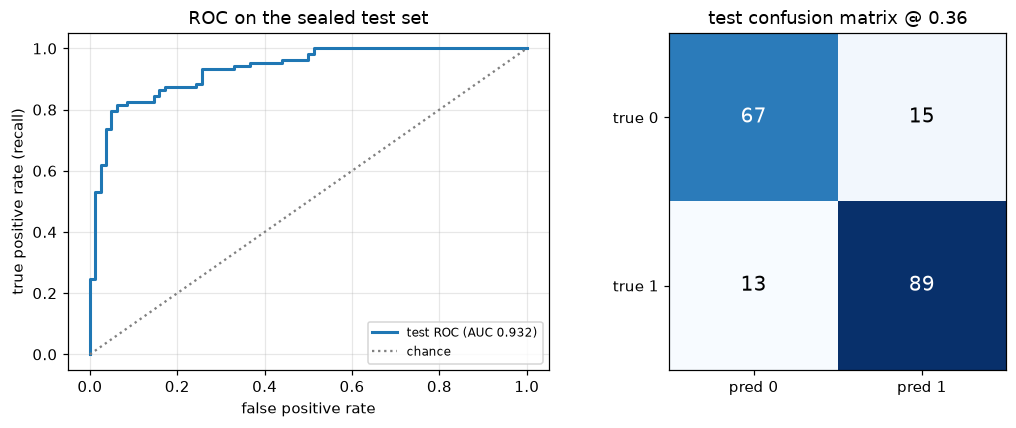

of 102 test patients with heart disease, 89 are caught and 13 missed
of 82 without, 15 are false alarms


In [17]:
te_prob = torch.sigmoid(final_net(X_te)).detach().numpy()
yt = y_te.numpy()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

fpr, tpr, _ = roc_curve(yt, te_prob)
ax[0].plot(fpr, tpr, lw=2,
           label=f"test ROC (AUC {roc_auc_score(yt, te_prob):.3f})")
ax[0].plot([0, 1], [0, 1], ls=":", c="grey", label="chance")
ax[0].set(xlabel="false positive rate", ylabel="true positive rate (recall)",
          title="ROC on the sealed test set")
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)

cm = confusion_matrix(yt, te_prob >= T_ACC)
ax[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[1].text(j, i, str(v), ha="center", va="center",
               color="white" if v > cm.max() / 2 else "black", fontsize=13)
ax[1].set(xticks=[0, 1], yticks=[0, 1],
          xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"],
          title=f"test confusion matrix @ {T_ACC:.2f}")
fig.tight_layout()
fig.savefig(FIGDIR / "fig_xavier_adam_test.png", bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"of {tp + fn} test patients with heart disease, {tp} are caught and {fn} missed")
print(f"of {tn + fp} without, {fp} are false alarms")

In [18]:
# Test predictions for model_comparison.ipynb.
# The hard labels are thresholded at 0.50, not at the validation-tuned T_ACC,
# so that every model in the project is compared at the same cutoff. The
# tuned-threshold numbers stay in the table above; baking 0.36 into this file
# would score this model at a different operating point from the baselines.
pd.DataFrame({
    "y_true":   yt.astype(int),
    "dnn_pred": (te_prob >= 0.50).astype(int),
    "dnn_prob": te_prob,
}).to_csv("models/dnn_xavier_adam_test_predictions.csv", index=False)

print("wrote models/dnn_xavier_adam_test_predictions.csv  (threshold 0.50)")


wrote models/dnn_xavier_adam_test_predictions.csv  (threshold 0.50)


## 9. Conclusions

**Selected model:** 4 hidden layers x 32 units, sigmoid activations, Xavier
(eq. 16) initialization, Adam at lr 3e-4. Weights restored from epoch 62, the
best validation AUC in a 92-epoch run.

**Test set (184 rows, evaluated once, after every choice was frozen):**

| threshold | AUC | accuracy | recall |
|---|---|---|---|
| 0.50 | 0.9316 | 0.8370 | 0.8235 |
| 0.36 (tuned on validation) | 0.9316 | 0.8478 | 0.8725 |

Majority-class accuracy is 0.5543, so the model sits about 29 points above
guessing. At threshold 0.36 it catches 89 of the 102 patients with heart
disease, misses 13, and raises 15 false alarms. Moving the threshold from 0.50
to 0.36 buys 5 extra catches for 2 extra false alarms; AUC is unchanged either
way, because it is computed from the ranking rather than the labels.

**Depth and learning rate make no measurable difference.** Best validation score
per depth:

| layers | AUC | accuracy | recall |
|---|---|---|---|
| 1 | 0.9340 | 0.8912 | 0.8889 |
| 2 | 0.9337 | 0.8980 | **0.9218** |
| 3 | 0.9330 | 0.8934 | 0.8971 |
| 4 | **0.9351** | 0.8912 | 0.8889 |
| 5 | 0.9339 | **0.8980** | 0.9012 |

Three different depths win the three metrics, which is what noise looks like.
Spread across all 20 configurations is 0.0025 AUC while seed-to-seed variation
within a single configuration is 0.0011, so depth 4 is the argmax rather than a
winner. The four learning rates from 3e-4 to 1e-2 land in the same band.

**Why performance plateaus.** Train AUC (0.9214) is *lower* than validation
(0.9355) and test (0.9316): the network cannot fit its own training data better
than unseen data, so it is not capacity-limited and additional layers have
nothing to contribute. Nor is it overfitting, despite 3,745 parameters against
587 training rows, because training stops at the best validation checkpoint.
With 147 validation and 184 test rows, one standard error on accuracy is about
2.6 points, so differences smaller than roughly 5 points cannot be resolved in
any case. The ceiling near 0.93 AUC appears to be a property of the dataset
rather than of the architecture.

**Summary.** Xavier initialization with Adam trains this sigmoid network reliably
at every depth tried: all 60 runs converged, none collapsed, and the saved model
generalizes with 0.9316 test AUC and 0.8725 recall at its tuned operating point.


## Artifacts this notebook writes:

| path | what |
|---|---|
| `models/dnn_xavier_adam.pt` | best-epoch weights + architecture metadata |
| `figures/fig_xavier_adam_depth_lr.png` | AUC and recall vs depth, per learning rate |
| `figures/fig_xavier_adam_training.png` | loss / AUC / recall curves, checkpoint marked |
| `figures/fig_xavier_adam_test.png` | test ROC and confusion matrix |
| `models/dnn_xavier_adam_test_predictions.csv` | test y_true / prob / pred at threshold 0.50 |